# 4. Matrices and the Ways to Multiply Them
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

The same map $T(x,y)=(x+y,x+y)$ seen in two bases. In the standard basis (left) the action looks like a shear-and-collapse onto the diagonal. In the basis $u_1=(1,1)$, $u_2=(1,-1)$ (right, grid aligned with $u_1,u_2$) it is transparent: stretch by $2$ along $u_1$, crush $u_2$ to zero. The red dots are a sample of points and their images (blue).

Text(0.5, 1.0, 'basis $u_1,u_2$: matrix diag$(2,0)$')

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


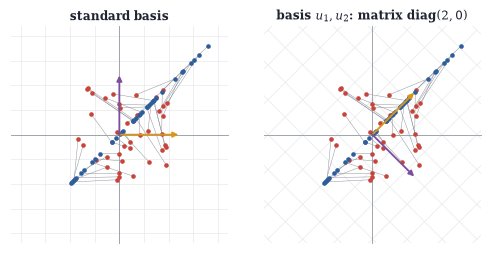

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

T = np.array([[1.0, 1.0], [1.0, 1.0]])
rng = np.random.default_rng(4); pts = rng.uniform(-1, 1, size=(2, 40))
fig, axs = plt.subplots(1, 2, figsize=(W, 2.2))
for ax, basis in zip(axs, [np.eye(2), np.array([[1.0, 1.0], [1.0, -1.0]]) / np.sqrt(2)]):
    plane(ax, 2.2, grid=False)
    grid_image(ax, basis, lim=3, n=13, color=LIGHT, lw=0.5, base=False)
    for p in pts.T:
        ax.plot(*np.vstack([p, T @ p]).T, color=GRAY, lw=0.3)
    ax.scatter(*pts, s=4, color=RED, zorder=3); ax.scatter(*(T @ pts), s=4, color=BLUE, zorder=3)
    arrow(ax, basis[:, 0] * 1.2, color=GOLD, lw=1.2); arrow(ax, basis[:, 1] * 1.2, color=PLUM, lw=1.2)
axs[0].set_title("standard basis")
axs[1].set_title(r"basis $u_1,u_2$: matrix diag$(2,0)$")

Two pictures of $Ax=b$ for $A=\begin{bmatrix}2&-1\\1&1\end{bmatrix}$ and $b=(1,5)$. Left, the column picture: $b$ is the combination $2\,a_1+3\,a_2$ of the columns $a_1=(2,1)$, $a_2=(-1,1)$. Right, the row picture: each equation $2x-y=1$, $x+y=5$ is a line, and the solution $x=(2,3)$ is where they cross.

Text(0.5, 1.0, 'row picture')

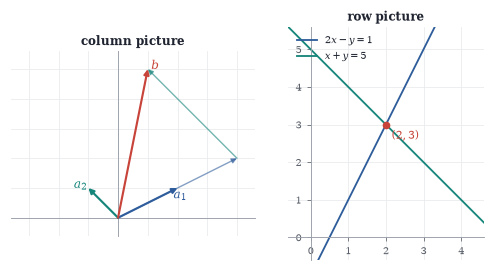

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *

A = np.array([[2.0, -1.0], [1.0, 1.0]]); b = np.array([1.0, 5.0])
x = np.linalg.solve(A, b)
fig, axs = plt.subplots(1, 2, figsize=(W, 2.35))
ax = plane(axs[0], (-3.6, 4.6, -0.6, 5.6), grid=True)
a1, a2 = A[:, 0], A[:, 1]
arrow(ax, a1, color=BLUE, label="$a_1$", offset=(0.1, -0.25)); arrow(ax, a2, color=TEAL, label="$a_2$", offset=(-0.25, 0.1))
arrow(ax, x[0] * a1, color=BLUE, lw=0.9, alpha=0.6)
arrow(ax, x[1] * a2, origin=x[0] * a1, color=TEAL, lw=0.9, alpha=0.6)
arrow(ax, b, color=RED, label="$b$", offset=(0.25, 0.1)); ax.set_title("column picture")
ax = plane(axs[1], (-0.6, 4.6, -0.6, 5.6), grid=True, ticks=True)
t = np.linspace(-1, 5, 2)
ax.plot(t, 2 * t - 1, color=BLUE, label="$2x-y=1$"); ax.plot(t, 5 - t, color=TEAL, label="$x+y=5$")
ax.plot(*x, "o", color=RED, ms=4); ax.text(x[0] + 0.15, x[1] - 0.4, "$(2,3)$", color=RED, fontsize=7)
ax.legend(loc="upper left"); ax.set_title("row picture")

The product of a $6\times3$ matrix and a $3\times6$ matrix as a sum of three outer products. Each piece $a_rb_r^{\mathsf T}$ (column of $A$ times row of $B$) has rank one, visible as a pattern in which every row is a multiple of one row and every column a multiple of one column. Their sum is the full product $AB$.

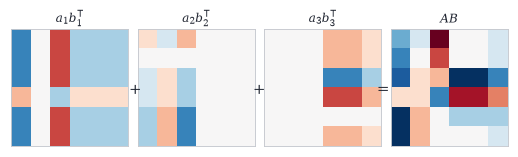

In [4]:
rng = np.random.default_rng(7)
A = rng.integers(-2, 3, size=(6, 3)).astype(float); B = rng.integers(-2, 3, size=(3, 6)).astype(float)
pieces = [np.outer(A[:, r], B[r]) for r in range(3)]
v = np.abs(A @ B).max()
fig, axs = plt.subplots(1, 4, figsize=(W, 1.45))
for r in range(3):
    heat(axs[r], pieces[r], annot=False, vmax=v); axs[r].set_title(rf"$a_{r+1}b_{r+1}^{{\mathsf{{T}}}}$")
heat(axs[3], A @ B, annot=False, vmax=v); axs[3].set_title("$AB$")
for k, s in enumerate(["+", "+", "="]):
    fig.text(0.255 + 0.245 * k, 0.45, s, fontsize=10, ha="center")

In [5]:
# The four orderings of the triple loop compute the same product.
def mm_inner(A, B):   # i, j, k : rows times columns
    m, n = A.shape; p = B.shape[1]; C = np.zeros((m, p))
    for i in range(m):
        for j in range(p):
            for k in range(n):
                C[i, j] += A[i, k] * B[k, j]
    return C
def mm_outer(A, B):   # k, i, j : columns times rows
    m, n = A.shape; p = B.shape[1]; C = np.zeros((m, p))
    for k in range(n):
        C += np.outer(A[:, k], B[k, :])
    return C
cols = lambda A, B: np.column_stack([A @ B[:, k] for k in range(B.shape[1])])
rows = lambda A, B: np.vstack([A[i, :] @ B for i in range(A.shape[0])])
C = A @ B
print([np.allclose(f(A, B), C) for f in (mm_inner, mm_outer, cols, rows)])

[True, True, True, True]


In [6]:
def cr_factor(A, tol=1e-10):
    """Greedy column-row factorization: keep each column not in the span of those kept."""
    keep = []
    for k in range(A.shape[1]):
        trial = keep + [k]
        if np.linalg.matrix_rank(A[:, trial], tol) == len(trial):
            keep = trial
    C = A[:, keep]
    R = np.linalg.lstsq(C, A, rcond=None)[0]          # coefficients of every column
    return C, R, keep
A = np.array([[1, 4, 5], [3, 2, 5], [2, 1, 3]], dtype=float)
C, R, keep = cr_factor(A)
print("basic columns:", keep); print("R =\n", R.round(10)); print("C @ R == A:", np.allclose(C @ R, A))

basic columns: [0, 1]
R =
 [[ 1. -0.  1.]
 [ 0.  1.  1.]]
C @ R == A: True


A synthetic $120\times120$ "photograph" (left) and its approximations by $1$, $4$ and $15$ rank-one plaids, chosen optimally by the singular value decomposition. Each additional term adds one horizontal-times-vertical pattern.

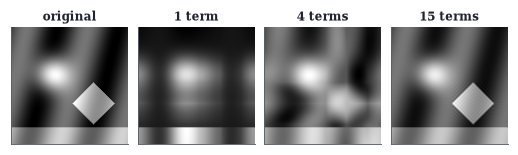

In [7]:
n = 120
y, x = np.mgrid[0:n, 0:n] / n
img = (np.exp(-((x - 0.35) ** 2 + (y - 0.4) ** 2) / 0.02) + 0.6 * (np.abs(x - 0.7) + np.abs(y - 0.65) < 0.18)
       + 0.25 * np.sin(12 * x + 3 * y) + 0.4 * (y > 0.85))
U, sv, Vt = np.linalg.svd(img)
fig, axs = plt.subplots(1, 4, figsize=(W, 1.35))
for ax, k in zip(axs, [None, 1, 4, 15]):
    approx = img if k is None else (U[:, :k] * sv[:k]) @ Vt[:k]
    ax.imshow(approx, cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("original" if k is None else f"{k} term" + ("s" if k > 1 else ""))

The skeleton factorization $A=CM\tilde R$ of a $40\times30$ matrix of rank $4$. The factor $C$ consists of four actual columns of $A$ and $\tilde R$ of four actual rows (chosen by column-pivoted QR, Chapter 36, so that they are far from dependent); $M$ is the inverse of the $4\times4$ block where they cross. The product reproduces $A$ to machine precision.

relative error of C M R~: 2.703511782456108e-16


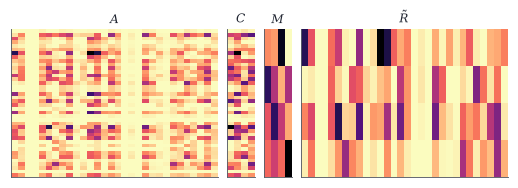

In [8]:
rng = np.random.default_rng(2)
A = np.maximum(rng.normal(size=(40, 4)), 0) @ np.maximum(rng.normal(size=(4, 30)), 0)   # nonnegative, rank 4
import scipy.linalg as sla
cols = sorted(sla.qr(A, pivoting=True)[2][:4])        # four well-separated columns
rws = sorted(sla.qr(A.T, pivoting=True)[2][:4])       # and four rows
C, Rt = A[:, cols], A[rws, :]
M = np.linalg.inv(A[np.ix_(rws, cols)])
fig, axs = plt.subplots(1, 4, figsize=(W, 1.6), gridspec_kw=dict(width_ratios=[30, 4, 4, 30]))
for ax, X, t in zip(axs, [A, C, M, Rt], ["$A$", "$C$", "$M$", r"$\tilde R$"]):
    ax.imshow(X, cmap="magma_r", aspect="auto"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(t)
print("relative error of C M R~:", np.linalg.norm(C @ M @ Rt - A) / np.linalg.norm(A))

The shapes of the five factorizations, drawn for a random $6\times6$ matrix (and its symmetric part for $Q\Lambda Q^{\mathsf T}$). Colour shows the sign and size of entries; white is zero. Triangular, orthogonal and diagonal factors each have their own visual signature.

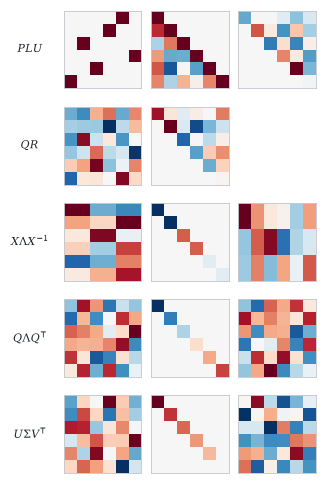

In [9]:
import scipy.linalg as sla
rng = np.random.default_rng(5)
A = rng.normal(size=(6, 6)); S = (A + A.T) / 2
P, L, U = sla.lu(A); Q, R = np.linalg.qr(A)
lam, X = np.linalg.eig(A); ls, Qs = np.linalg.eigh(S); Us, sv, Vt = np.linalg.svd(A)
rowsf = [("$PLU$", [P, L, U]), ("$QR$", [Q, R]), (r"$X\Lambda X^{-1}$", [np.real(X), np.diag(np.real(lam)), np.real(np.linalg.inv(X))]),
         (r"$Q\Lambda Q^{\mathsf{T}}$", [Qs, np.diag(ls), Qs.T]), (r"$U\Sigma V^{\mathsf{T}}$", [Us, np.diag(sv), Vt])]
fig, axs = plt.subplots(5, 3, figsize=(W * 0.62, W * 0.95))
for i, (name, fs) in enumerate(rowsf):
    for j in range(3):
        ax = axs[i, j]
        if j < len(fs):
            heat(ax, fs[j], annot=False)
        else:
            ax.axis("off")
    axs[i, 0].set_ylabel(name, rotation=0, labelpad=22, fontsize=7.5, va="center")

In [10]:
# Walks of length 3 on a 4-cycle 0-1-2-3-0 counted by A^3, and checked by brute force.
import itertools
A = np.zeros((4, 4), int)
for i in range(4):
    A[i, (i + 1) % 4] = A[(i + 1) % 4, i] = 1
A3 = np.linalg.matrix_power(A, 3)
brute = np.zeros((4, 4), int)
for j, p, r, k in itertools.product(range(4), repeat=4):
    brute[j, k] += A[j, p] * A[p, r] * A[r, k]
print(A3); print("matches brute force:", (A3 == brute).all())

[[0 4 0 4]
 [4 0 4 0]
 [0 4 0 4]
 [4 0 4 0]]
matches brute force: True


Three ways to complete a parallelogram from the vertices $(1,1)$, $(4,2)$, $(1,3)$ (black). Each fourth vertex is $q+r-p$ for a different choice of the vertex $p$ opposite it.

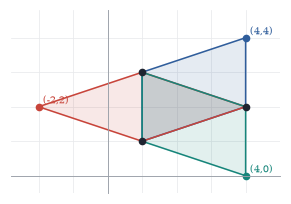

In [11]:
P = np.array([[1, 1], [4, 2], [1, 3]], float)
fig, ax = plt.subplots(figsize=(W * 0.55, 2.2))
plane(ax, (-2.8, 5, -0.5, 4.8), grid=True)
for k, col in zip(range(3), [BLUE, RED, TEAL]):
    p = P[k]; q, r = P[(k + 1) % 3], P[(k + 2) % 3]
    d = q + r - p
    poly = np.array([p, q, d, r, p])
    ax.fill(*poly.T, color=col, alpha=0.12); ax.plot(*poly.T, color=col, lw=1)
    ax.plot(*d, "o", color=col, ms=4); ax.text(d[0] + 0.12, d[1] + 0.1, f"({d[0]:g},{d[1]:g})", fontsize=6.5, color=col)
ax.plot(*P.T, "o", color=INK, ms=4)

In [12]:
for A in [np.array([[1, 3, -2], [3, 9, -6], [2, 6, -4]], float), np.arange(1, 10, dtype=float).reshape(3, 3)]:
    C, R, keep = cr_factor(A)
    print("basic columns", keep, " rank", len(keep), "\nR =\n", R.round(10), "\n")

basic columns [0]  rank 1 
R =
 [[ 1.  3. -2.]] 

basic columns [0, 1]  rank 2 
R =
 [[ 1. -0. -1.]
 [ 0.  1.  2.]] 



In [13]:
for A, rws, cls in [(np.array([[1, 2], [3, 6], [2, 4.]]), [0], [0]), (np.array([[1, 2], [3, 4], [5, 6.]]), [0, 1], [0, 1])]:
    C, Rt = A[:, cls], A[rws, :]
    M1 = np.linalg.inv(C.T @ C) @ C.T @ A @ Rt.T @ np.linalg.inv(Rt @ Rt.T)
    M2 = np.linalg.inv(A[np.ix_(rws, cls)])
    print("M from formula:\n", M1.round(10), "\nM = W^{-1}:", np.allclose(M1, M2), "  A = C M R~:", np.allclose(C @ M1 @ Rt, A))

M from formula:
 [[1.]] 
M = W^{-1}: True   A = C M R~: True
M from formula:
 [[-2.   1. ]
 [ 1.5 -0.5]] 
M = W^{-1}: True   A = C M R~: True


In [14]:
from functools import lru_cache
dims = [10, 100, 5, 50, 1]
@lru_cache(None)
def best(i, j):                     # cheapest cost of multiplying A_i ... A_j (0-based)
    if i == j:
        return 0, f"A{i+1}"
    return min((best(i, k)[0] + best(k + 1, j)[0] + dims[i] * dims[k + 1] * dims[j + 1],
                f"({best(i, k)[1]} {best(k + 1, j)[1]})") for k in range(i, j))
print(best(0, 3))

(1750, '(A1 (A2 (A3 A4)))')
